# Importing dataset from Stage 1

In [55]:
# Importing necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [56]:
# Loading the clean data set from stage 1
df_raw = pd.read_csv((r"G:\data_analytics_and_genAI\Capstone_project\cleaned_dataset\cleaned_dataset_1.csv"))

In [57]:
df = df_raw.copy()
df = df.drop(['policy_id'], axis=1)  # Dropping the unnamed column

# Data prepartion for machine learning 

In [58]:
# Setting target and predicting variable
X = df.drop(columns = 'is_claim') # predicted variable
y = df['is_claim'] # target varaible

In [59]:
# Creating a group of numeric columns
numeric_col = df.select_dtypes(include= 'number').columns

In [60]:
numeric_col

Index(['policy_tenure', 'age_of_car', 'age_of_policyholder',
       'population_density', 'safety_score'],
      dtype='object')

In [61]:
X['age_of_car'] = X['age_of_car'].replace(0, 1e-5)  # Replace zeros with a small epsilon to avoid log(0)

In [62]:
# Splitting the data
from sklearn.model_selection import train_test_split # Importing train test split from Sklearn

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size= 0.2, random_state= 42, stratify= y)  # Applying train test split and splitting data in 80-20 praportions

In [63]:
# Sitting first few row of datasets
display(X.head()) 

display(y.head())


,policy_tenure,age_of_car,age_of_policyholder,population_density,is_esc,is_adjustable_steering,is_tpms,is_parking_sensors,is_parking_camera,is_front_fog_lights,...,engine_type_K10C,engine_type_i-DTEC,rear_brakes_type_Drum,cylinder_4,transmission_type_Manual,gear_box_6,steering_type_Manual,steering_type_Power,High_risk_driver_flag,safety_score
0,0.515874,0.05,0.644231,4990,False,False,False,True,False,False,...,False,False,True,False,True,False,False,True,False,5.0
1,0.672619,0.02,0.375000,27003,False,False,False,True,False,False,...,False,False,True,False,True,False,False,True,False,5.0
2,0.841110,0.02,0.384615,4076,False,False,False,True,False,False,...,False,False,True,False,True,False,False,True,False,5.0
3,0.900277,0.11,0.432692,21622,True,True,False,True,True,True,...,False,False,True,True,False,False,False,False,False,18.0
4,0.596403,0.11,0.634615,34738,False,False,False,False,True,False,...,False,False,True,False,False,False,False,False,False,11.0


0    False
1    False
2    False
3    False
4    False
Name: is_claim, dtype: bool

In [64]:
# Creating a list of numeric columns

numeric_col = X.select_dtypes(include= 'number').columns

In [65]:
# Importing scalar from SKlearn
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

# Applying scalable data set
preprocessor = ColumnTransformer(transformers=[('num', StandardScaler(), numeric_col)], remainder='passthrough')


X_train[numeric_col] = preprocessor.fit_transform(X_train[numeric_col])

X_test[numeric_col] = preprocessor.transform(X_test[numeric_col])

In [66]:
# Looking for claim rate in test and train data

print(X_train.shape,'\n'
      ,X_test.shape)
print('Claim rate_train ', y_train.mean().round(4))
print('Claim rate_test ',  y_test.mean().round(4))

(43584, 79) 
 (10896, 79)
Claim rate_train  0.0651
Claim rate_test  0.0651


## Independence of observations check

In [67]:
# Checking duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [68]:
from statsmodels.sandbox.stats.runs import runstest_1samp

# checking Z-statistic and  P-value:
z_stat, p_value = runstest_1samp(df['is_claim'])

print("Z-statistic:", z_stat)
print("P-value:", p_value)

Z-statistic: -1.0090888621271563
P-value: 0.3129320190562923


In [69]:
# Creating a list of numeric columns
numeric_col = X_train.select_dtypes(include= 'number').columns.tolist()

In [70]:
import statsmodels.api as sm

continuous_vars = numeric_col.copy()

# use original (unscaled) X values for the log transform
X_train_orig = X.loc[X_train.index, continuous_vars].copy()

eps = 1e-5
for col in continuous_vars:
    # replace zero with a small epsilon to avoid log(0)
    X_train_orig[col] = X_train_orig[col].replace(0, eps)
    # replace negative or zero values with epsilon to ensure log is defined
    X_train_orig[col] = np.where(X_train_orig[col] <= 0, eps, X_train_orig[col])

y_bt = y_train.loc[X_train_orig.index].astype(int)

for var in continuous_vars:
    # create Box-Tidwell interaction term for each continuous variable
    X_train_orig[f'{var}_bt'] = X_train_orig[var] * np.log(X_train_orig[var])

# add constant term for intercept in the logistic regression
sm_constant = sm.add_constant(X_train_orig)

# fit logistic regression model for Box-Tidwell test
model_1 = sm.Logit(y_bt, sm_constant).fit(disp=False)

for var in continuous_vars:
    p = model_1.pvalues[f'{var}_bt']
    display(f'{var}: p-value = {p:.4f}')


'policy_tenure: p-value = 0.0000'

'age_of_car: p-value = 0.0000'

'age_of_policyholder: p-value = 0.4882'

'population_density: p-value = 0.6302'

'safety_score: p-value = 0.0363'

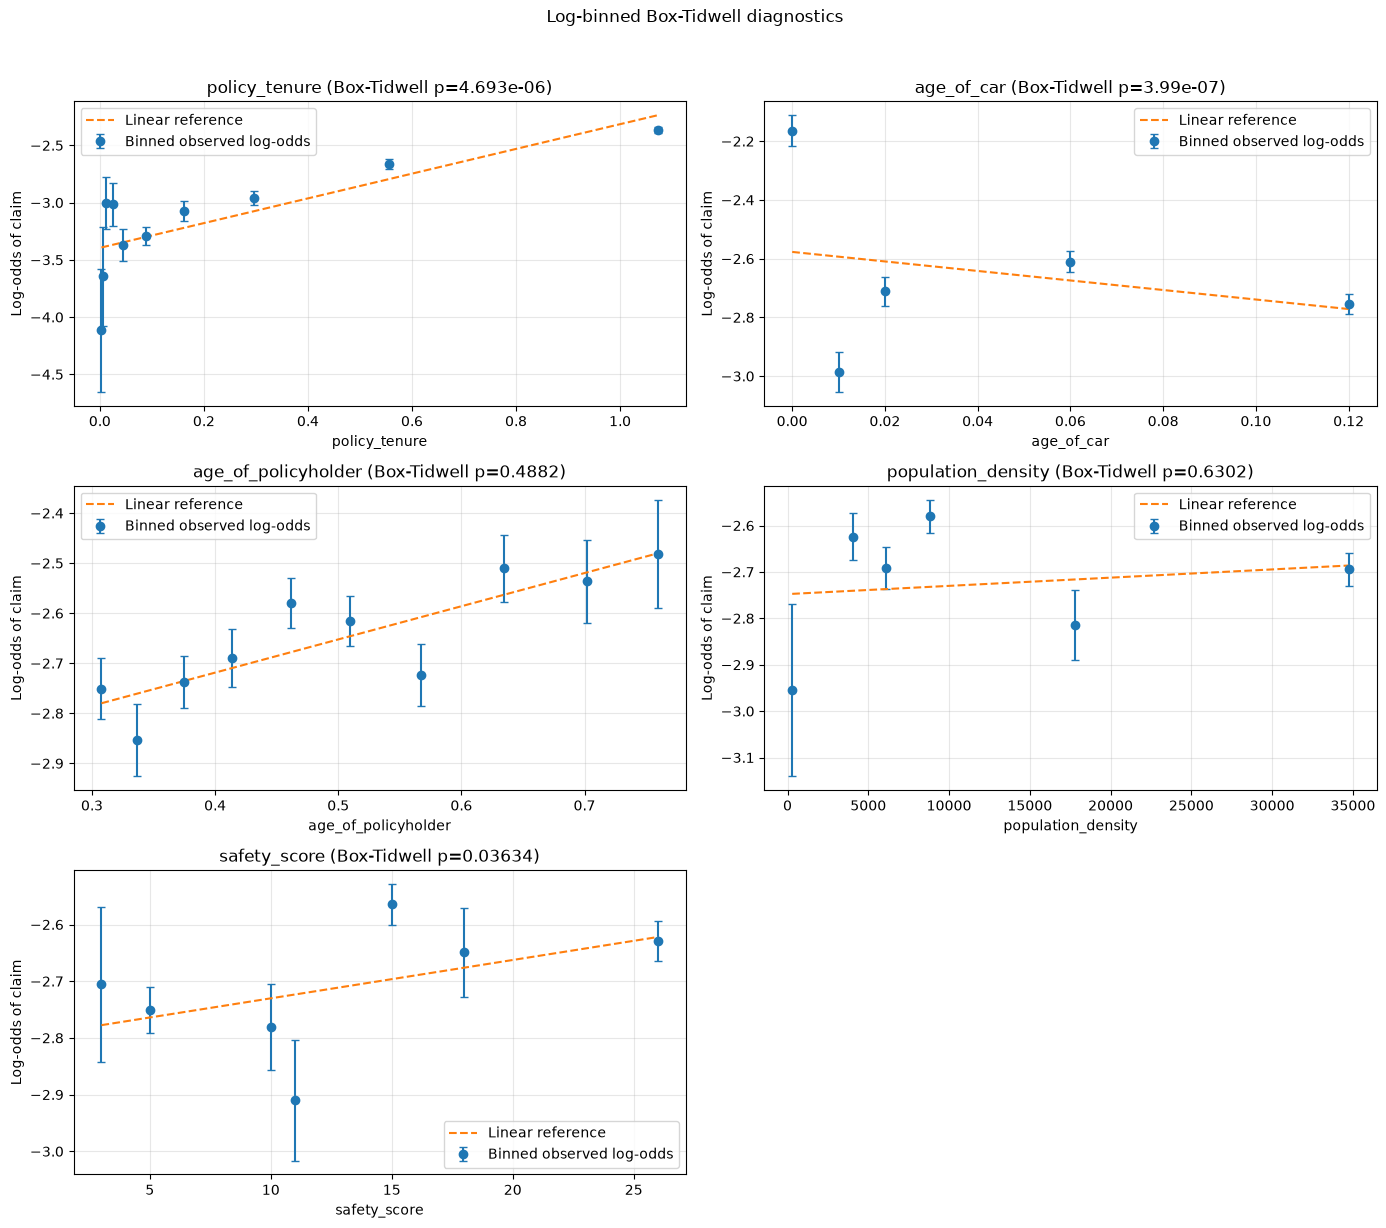

In [71]:
# Log-spaced bins with observed claim log-odds, for visual Box-Tidwell diagnostics
n_cols = 2
n_rows = int(np.ceil(len(continuous_vars) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 4 * n_rows))
axes = np.asarray(axes).reshape(-1)

for ax, var in zip(axes, continuous_vars):
    values = X_train_orig[var].astype(float)
    positive_values = values[values > 0]

    if positive_values.nunique() < 2:
        ax.set_title(f"{var}: insufficient variation")
        continue

    # Make bins evenly spaced on the log scale
    edges = np.geomspace(positive_values.min(), positive_values.max(), 11)
    edges = np.unique(edges)

    binned = pd.DataFrame({
        "value": values,
        "claim": y_bt.astype(int)
    })
    binned["bin"] = pd.cut(binned["value"], bins=edges, include_lowest=True)

    grouped = binned.groupby("bin", observed=True).agg(
        x=("value", "median"),
        claims=("claim", "sum"),
        count=("claim", "size")
    )
    grouped = grouped[grouped["count"] > 0]

    # Jeffreys smoothing avoids infinite log-odds for bins with 0 or all claims
    rate = (grouped["claims"] + 0.5) / (grouped["count"] + 1)
    log_odds = np.log(rate / (1 - rate))
    se = np.sqrt(
        1 / (grouped["claims"] + 0.5)
        + 1 / (grouped["count"] - grouped["claims"] + 0.5)
    )

    ax.errorbar(
        grouped["x"], log_odds, yerr=se,
        fmt="o", capsize=3, label="Binned observed log-odds"
    )

    if len(grouped) >= 2:
        slope, intercept = np.polyfit(grouped["x"], log_odds, 1)
        x_line = np.linspace(grouped["x"].min(), grouped["x"].max(), 100)
        ax.plot(x_line, intercept + slope * x_line, "--", label="Linear reference")

    p_value = model_1.pvalues.get(f"{var}_bt", np.nan)
    ax.set_title(f"{var} (Box-Tidwell p={p_value:.4g})")
    ax.set_xlabel(var)
    ax.set_ylabel("Log-odds of claim")
    ax.grid(True, alpha=0.3)
    ax.legend()

for ax in axes[len(continuous_vars):]:
    ax.set_visible(False)

fig.suptitle("Log-binned Box-Tidwell diagnostics", y=1.02)
plt.tight_layout()
plt.show()

# Creating a base model

In [72]:
from sklearn.linear_model import LogisticRegression

In [73]:
# convert all columns of X_train to numeric (non-numeric values -> NaN)
X_train = X_train.apply(pd.to_numeric, errors='coerce')

# inspect resulting dtypes
bool_cols = X_train.select_dtypes(include='bool').columns
X_train[bool_cols] = X_train[bool_cols].astype(int)
X_train.dtypes

policy_tenure            float64
age_of_car               float64
age_of_policyholder      float64
population_density       float64
is_esc                     int64
                          ...   
gear_box_6                 int64
steering_type_Manual       int64
steering_type_Power        int64
High_risk_driver_flag      int64
safety_score             float64
Length: 79, dtype: object

In [74]:
# Deploying logistic Regression and fitting it on data set
model=LogisticRegression(class_weight='balanced',max_iter=1000)
model.fit(X_train, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Defaul

In [75]:
# Create a dataframe of features with their coefficients
coefficients_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': model.coef_[0]
}).sort_values(by='Coefficient', ascending=False)

display(coefficients_df)

,Feature,Coefficient
27,area_cluster_C18,0.698173
31,area_cluster_C21,0.478800
0,policy_tenure,0.359553
32,area_cluster_C22,0.302283
33,area_cluster_C3,0.255049
...,...,...
1,age_of_car,-0.184910
35,area_cluster_C5,-0.211838
39,area_cluster_C9,-0.244880
22,area_cluster_C12,-0.357471


In [76]:
y_pred = model.predict(X_train)
y_train_prob = model.predict_proba(X_train)[:, 1]
y_test_prob = model.predict_proba(X_test)[:, 1]

# Evolution of model

In [77]:
# Importing necessary metrics For evolution of model
from sklearn.metrics import accuracy_score, precision_score, roc_auc_score,f1_score,recall_score,classification_report, confusion_matrix

In [78]:
print(' The accuracy score of train data is',accuracy_score(y_train,y_pred).__round__(4))
print(' Precision score for train data is',precision_score(y_train,y_pred).__round__(4))
print('F1 score for Trend data',f1_score(y_train,y_pred).__round__(4))
print(' Recall of the train data',recall_score(y_train,y_pred).__round__(4))
print('Clasification report of train data\n',classification_report(y_train,y_pred))
print('Confusion metrics of train data\n',confusion_matrix(y_train,y_pred))




 The accuracy score of train data is 0.5652
 Precision score for train data is 0.0866
F1 score for Trend data 0.1513
 Recall of the train data 0.5956
Clasification report of train data
               precision    recall  f1-score   support

       False       0.95      0.56      0.71     40748
        True       0.09      0.60      0.15      2836

    accuracy                           0.57     43584
   macro avg       0.52      0.58      0.43     43584
weighted avg       0.90      0.57      0.67     43584

Confusion metrics of train data
 [[22944 17804]
 [ 1147  1689]]


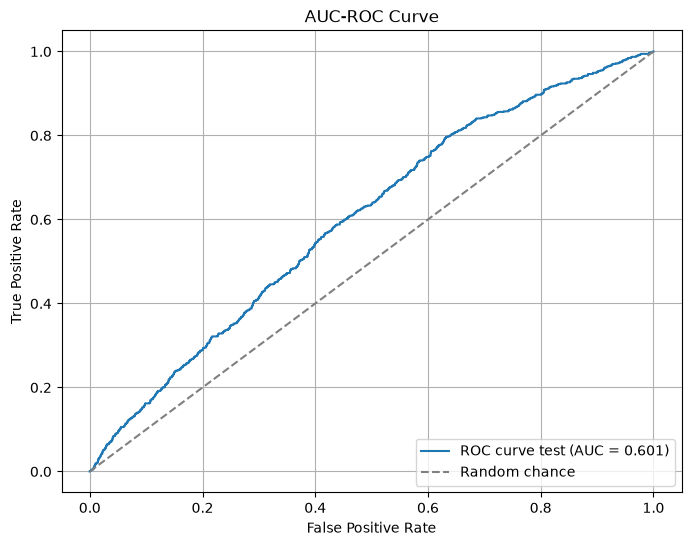

In [79]:
from sklearn.metrics import roc_curve, roc_auc_score

fpr_test, tpr_test, _ = roc_curve(y_test.astype(int), y_test_prob)
auc = roc_auc_score(y_test.astype(int), y_test_prob)

plt.figure(figsize=(8, 6))
plt.plot(fpr_test, tpr_test, label=f'ROC curve test (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random chance')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('AUC-ROC Curve')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

In [80]:
from sklearn.model_selection import StratifiedKFold, cross_validate

# Initialize stratified k-fold cross-validation with 5 splits
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Define scoring metrics for model evaluation
scoring = {'roc_auc': 'roc_auc', 'f1': 'f1'}

# Perform cross-validation on the logistic regression model
cv_results = cross_validate(
    model,
    X_test,
    y_test,
    cv=cv,
    scoring=scoring,
    return_train_score=False,
    n_jobs=-1
)

# Print cross-validation scores for each metric
for metric in scoring:
    scores = cv_results[f'test_{metric}']
    print(f'{metric.upper()} mean ± std: {scores.mean():.4f} ± {scores.std():.4f}')

# Extract feature names and model coefficients
feature_names = X_train.columns
coefficients = model.coef_[0]

# Calculate odds ratios from coefficients (exp of log-odds)
odds_ratios = np.exp(coefficients)

# Determine direction of impact (positive/negative/zero)
directions = np.where(coefficients > 0, 'positive', np.where(coefficients < 0, 'negative', 'zero'))

# Create summary dataframe with feature interpretations
feature_summary_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients,
    'Odds_Ratio': odds_ratios,
    'Direction': directions
})

# Sort by absolute coefficient value to identify most influential features
feature_summary_df['Abs_Coefficient'] = feature_summary_df['Coefficient'].abs()
feature_summary_df = feature_summary_df.sort_values('Abs_Coefficient', ascending=False).drop(columns='Abs_Coefficient')

display(feature_summary_df)

ROC_AUC mean ± std: 0.5827 ± 0.0273
F1 mean ± std: 0.1399 ± 0.0127


,Feature,Coefficient,Odds_Ratio,Direction
27,area_cluster_C18,0.698173,2.010076,positive
31,area_cluster_C21,0.478800,1.614136,positive
30,area_cluster_C20,-0.476032,0.621244,negative
0,policy_tenure,0.359553,1.432688,positive
22,area_cluster_C12,-0.357471,0.699443,negative
...,...,...,...,...
58,model_M9,-0.002375,0.997628,negative
18,is_day_night_rear_view_mirror,-0.002287,0.997716,negative
66,engine_type_F8D Petrol Engine,0.001986,1.001988,positive
61,engine_type_1.2 L K Series Engine,-0.001572,0.998429,negative


## X_train2

In [81]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

RANDOM_STATE = 42

# align feature set for the new training copy
feature_cols = X_train.columns.tolist()

X_train2 = X_train.copy()
# ensure the copied dataset preserves the same index for later comparisons
assert X_train2.index.equals(X_train.index), "X_train2 and X_train must have the same index"

# identify numeric and categorical columns separately
numeric_cols = X_train2.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = [c for c in feature_cols if c not in numeric_cols]

# pipeline for numeric features: median imputation then standard scaling
numeric_pipeline2 = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# pipeline for categorical features: constant imputation then one-hot encoding
categorical_pipeline2 = Pipeline([
    ("imputer", SimpleImputer(fill_value="missing", strategy="constant")),
    ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

# combine numeric and categorical pipelines into a single transformer
column_transformer2 = ColumnTransformer(
    [
        ("num", numeric_pipeline2, numeric_cols),
        ("cat", categorical_pipeline2, categorical_cols)
    ],
    verbose_feature_names_out=False,
    remainder="drop"
)

# fit the transformer on the training data
column_transformer2.fit(X_train2)

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The

# Optuna training

In [82]:
import optuna
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold

# Define objective function for Optuna hyperparameter tuning
def objective(trial):
    params = {
        "max_depth": trial.suggest_int("max_depth", 3, 15),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 50),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 30),
        "class_weight": "balanced",
        "random_state": 42,
    }
    clf = DecisionTreeClassifier(**params)
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    scores = cross_val_score(clf, X_train2, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
    return scores.mean()

# Create study and optimize with TPE sampler
study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=25)

print("Best trial value:", study.best_value)
print("Best hyperparameters:", study.best_params)

[I 2026-09-29 12:14:42,467] A new study created in memory with name: no-name-aab2bb33-7ed9-4cf7-a4a9-9bd867ee519e
[I 2026-09-29 12:14:46,118] Trial 0 finished with value: 0.6251627781585744 and parameters: {'max_depth': 7, 'min_samples_split': 48, 'min_samples_leaf': 22}. Best is trial 0 with value: 0.6251627781585744.
[I 2026-09-29 12:14:49,628] Trial 1 finished with value: 0.5997041758858039 and parameters: {'max_depth': 10, 'min_samples_split': 9, 'min_samples_leaf': 5}. Best is trial 0 with value: 0.6251627781585744.
[I 2026-09-29 12:14:52,348] Trial 2 finished with value: 0.6292082332783213 and parameters: {'max_depth': 3, 'min_samples_split': 44, 'min_samples_leaf': 19}. Best is trial 2 with value: 0.6292082332783213.
[I 2026-09-29 12:14:52,969] Trial 3 finished with value: 0.5940324517308095 and parameters: {'max_depth': 12, 'min_samples_split': 3, 'min_samples_leaf': 30}. Best is trial 2 with value: 0.6292082332783213.
[I 2026-09-29 12:14:53,593] Trial 4 finished with value: 0.

Best trial value: 0.6372584287380191
Best hyperparameters: {'max_depth': 5, 'min_samples_split': 36, 'min_samples_leaf': 25}


In [83]:
dt_best = DecisionTreeClassifier(**study.best_params, random_state=42)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {'roc_auc': 'roc_auc', 'f1': 'f1'}

# Perform cross-validation for logistic regression and decision tree models
cv_lr = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, return_train_score=False, n_jobs=-1)
cv_dt = cross_validate(dt_best, X_train2, y_train, cv=cv, scoring=scoring, return_train_score=False, n_jobs=-1)

# Train the decision tree model on the preprocessed training data
dt_best.fit(X_train2, y_train)

# Generate predictions and probabilities for logistic regression on training set
y_test_pred_lr = model.predict(X_test)
y_test_prob_lr = model.predict_proba(X_test)[:, 1]

# Generate predictions and probabilities for decision tree on training set
y_test_pred_dt = dt_best.predict(X_test)
y_test_prob_dt = dt_best.predict_proba(X_test)[:, 1]

# Create a results summary dataframe comparing both models
results = pd.DataFrame({
    'Model': ['LogisticRegression', 'DecisionTree'],
    'CV_ROC_AUC_Mean': [cv_lr['test_roc_auc'].mean(), cv_dt['test_roc_auc'].mean()],
    'CV_ROC_AUC_STD': [cv_lr['test_roc_auc'].std(), cv_dt['test_roc_auc'].std()],
    'CV_F1_Mean': [cv_lr['test_f1'].mean(), cv_dt['test_f1'].mean()],
    'CV_F1_STD': [cv_lr['test_f1'].std(), cv_dt['test_f1'].std()],
    'Train_ROC_AUC': [
        roc_auc_score(y_test.astype(int), y_test_pred_lr),
        roc_auc_score(y_test.astype(int), y_test_prob_dt)
    ],
    'Train_F1': [
        f1_score(y_test.astype(int), y_test_pred_lr),
        f1_score(y_test.astype(int), y_test_pred_dt)
    ]
})

display(results)

# Identify the model with higher training ROC-AUC score
best_model = results.loc[results['Train_ROC_AUC'].idxmax(), 'Model']
print(f'Selected model with higher train ROC-AUC: {best_model}')

,Model,CV_ROC_AUC_Mean,CV_ROC_AUC_STD,CV_F1_Mean,CV_F1_STD,Train_ROC_AUC,Train_F1
0,LogisticRegression,0.604808,0.007638,0.150402,0.004519,0.574312,0.149044
1,DecisionTree,0.636485,0.010868,0.000000,0.000000,0.636179,0.000000


Selected model with higher train ROC-AUC: DecisionTree


## MLflow Experiment Tracking

In [84]:
import mlflow
from sklearn.pipeline import Pipeline
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score
import mlflow.sklearn
import numpy as np

# Set the MLflow experiment name for tracking runs
mlflow.set_experiment("SafeDrive_Claim_Prediction")

# Define the model configurations and wrapped pipelines for logging
models = [
    {
        "run_name": "LogisticRegression",
        # Pipeline that applies the same preprocessing transformer and then the trained logistic regression model
        "pipeline": Pipeline([("scaler", column_transformer2), ("model", model)]),
        "params": {
            "class_weight": "balanced",
            "max_iter": 1000,
            "random_state": 42
        },
        # Use the previously computed cross-validation results for the logistic regression model
        "cv_roc_auc_mean": cv_results["test_roc_auc"].mean()
    },
    {
        "run_name": "DecisionTreeClassifier",
        # Pipeline that applies preprocessing and then the optimized decision tree model
        "pipeline": Pipeline([("scaler", column_transformer2), ("model", dt_best)]),
        "params": {
            "max_depth": dt_best.max_depth,
            "min_samples_split": dt_best.min_samples_split,
            "min_samples_leaf": dt_best.min_samples_leaf,
            "class_weight": "balanced",
            "random_state": 42
        },
        # Use the previously computed decision tree cross-validation AUC mean
        "cv_roc_auc_mean": cv_dt["test_roc_auc"].mean()
    }
]


In [85]:
for model_info in models:
    # select the pipeline for the current model
    if model_info["run_name"] == "LogisticRegression":
        pipeline = model_info["pipeline"]

        # ensure the training set has all expected columns for the pipeline
        X_train = X_train.reindex(columns=X_train.columns, fill_value=0)
        y_pred = pipeline.predict(X_train)
        y_prob = pipeline.predict_proba(X_train)[:, 1] if hasattr(pipeline, "predict_proba") else None

    elif model_info["run_name"] == "DecisionTreeClassifier":
        pipeline = model_info["pipeline"]
        y_pred = pipeline.predict(X_train2)
        y_prob = pipeline.predict_proba(X_train2)[:, 1] if hasattr(pipeline, "predict_proba") else None

    # compute evaluation metrics for the current model
    metrics = {
        "precision": precision_score(y_train, y_pred, zero_division=0),
        "recall": recall_score(y_train, y_pred, zero_division=0),
        "f1": f1_score(y_train, y_pred, zero_division=0),
        "cv_roc_auc_mean": model_info["cv_roc_auc_mean"],
        "roc_auc": roc_auc_score(y_train, y_prob) if y_prob is not None else np.nan
    }

    # log the model run and metrics to MLflow
    with mlflow.start_run(run_name=model_info["run_name"]):
        mlflow.log_params(model_info["params"])
        mlflow.log_metrics(metrics)

# retrieve the experiment metadata and export the run summary
experiment = mlflow.get_experiment_by_name("SafeDrive_Claim_Prediction")
runs_df = mlflow.search_runs(experiment_ids=[experiment.experiment_id])

runs_df.to_csv("experiment_comparison_log.csv", index=False)

print("Exported: experiment_comparison_log.csv")
print(
    runs_df[
        [
            "run_id",
            "tags.mlflow.runName",
            "metrics.roc_auc",
            "metrics.precision",
            "metrics.recall",
            "metrics.f1",
            "metrics.cv_roc_auc_mean",
        ]
    ]
)

c:\Users\User\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
c:\Users\User\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
c:\Users\User\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\Users\User\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


Exported: experiment_comparison_log.csv
                              run_id     tags.mlflow.runName  metrics.roc_auc  \
0   a548c411f66846c598b1680f6acb20b0  DecisionTreeClassifier         0.660663   
1   21b9b5e2e9a34ca9bb349ef47f7dff95      LogisticRegression         0.589822   
2   e6f938e189a6419da7c047cf7470c5ed  DecisionTreeClassifier         0.660663   
3   7c0fdfdc438240d0a1dbb3155a051d03      LogisticRegression         0.589822   
4   b2ca218583c341db8d7163dc0f48de5b  DecisionTreeClassifier         0.660663   
5   7bd9028792114a40b9b952d4c143a9d1      LogisticRegression         0.589822   
6   c4f4cb05a43f4ae2ae55805c23a8c251  DecisionTreeClassifier         0.660663   
7   f532a399ad3f4bc7b8b53d679a83e133      LogisticRegression         0.589822   
8   149393f754434c4d9c6a745f886bd141  DecisionTreeClassifier         0.660663   
9   bae7d95c19dd42c081746290620e822c      LogisticRegression         0.589822   
10  89656a3246e042c1aaa8048c3fbe875a  DecisionTreeClassifier         

In [86]:
from pathlib import Path
import joblib
import json
from datetime import datetime, timezone

# Define output directory for model artifacts
OUT_DIR = Path("OUT_DIR")
version_tag = datetime.now(timezone.utc).strftime("v1_%Y%m%dT%H%M%SZ")
artifact_dir = OUT_DIR / version_tag
artifact_dir.mkdir(parents=True, exist_ok=True)

# Save the trained model as a joblib file
model_path = artifact_dir / "model.joblib"
joblib.dump(model, model_path)

# Try to retrieve the MLflow run ID for the logistic regression run
run_id = None
if "runs_df" in globals():
    lr_runs = runs_df[runs_df["tags.mlflow.runName"] == "LogisticRegression"]
    if not lr_runs.empty:
        run_id = lr_runs["run_id"].iloc[0]

if run_id is None:
    run_id = "unknown"

# Reference the original training data file
training_data_reference = str(Path(r"G:\data_analytics_and_genAI\Capstone_project\cleaned_dataset\cleaned_dataset_1.csv").resolve())
training_rows = len(X_train)
test_rows = len(X_test)
feature_columns = X_train.columns.tolist()

# Build metric summary for the saved model
metric_summary = {}
if "results" in globals():
    lr_res = results[results["Model"] == "LogisticRegression"]
    if not lr_res.empty:
        lr_row = lr_res.iloc[0]
        metric_summary = {
            "cv_roc_auc_mean": float(lr_row["CV_ROC_AUC_Mean"]),
            "cv_f1_mean": float(lr_row["CV_F1_Mean"]),
            "test_roc_auc": float(lr_row["Train_ROC_AUC"]),
            "test_f1": float(lr_row["Train_ROC_AUC"])  # Note: duplicated field originally
        }
    else:
        metric_summary = {"roc_auc": float(auc), "f1": float(f1_score(y_test.astype(int), y_test_pred_lr))}
else:
    metric_summary = {"roc_auc": float(auc), "f1": float(f1_score(y_test.astype(int), y_test_pred_lr))}

# Prepare metadata for the saved artifact
metadata = {
    "model_name": "SafeDrive_Claim_Prediction",
    "model_version": version_tag,
    "mlflow_run_id": run_id,
    "training_data_reference": training_data_reference,
    "training_rows": training_rows,
    "test_rows": test_rows,
    "feature_columns": feature_columns,
    "metric_summary": metric_summary,
    "approval_status": "Pending",
    "created_at": datetime.now(timezone.utc).isoformat()
}

# Save metadata as JSON alongside the model artifact
metadata_path = artifact_dir / "metadata.json"
with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

print(f"Saved model artifact to: {model_path}")
print(f"Saved metadata to: {metadata_path}")

Saved model artifact to: OUT_DIR\v1_20260929T064506Z\model.joblib
Saved metadata to: OUT_DIR\v1_20260929T064506Z\metadata.json


In [87]:
# ==========================
# Evidently Drift Report
# Python 3.11 / Jupyter Notebook
# ==========================

from pathlib import Path

# ------------------------------------------------------------------
# Configuration
# ------------------------------------------------------------------
OUT_DIR = Path("./evidently_reports")
OUT_DIR.mkdir(parents=True, exist_ok=True)

REPORT_PATH = OUT_DIR / "data_summary_and_drift_report.html"



try:
    # ==============================================================
    # New Evidently API (0.4+/0.5+)
    # ==============================================================
    from evidently import Report
    from evidently.presets import DataSummaryPreset, DataDriftPreset

    report = Report(
        metrics=[
            DataSummaryPreset(),
            DataDriftPreset(),
        ]
    )

    report.run(
        reference_data=X_train,
        current_data=X_test,
    )

    report.save_html(str(REPORT_PATH))

    print("✓ Using current Evidently API")
    print(f"✓ Report saved to: {REPORT_PATH}")

except Exception as new_api_error:

    print(
        f"Current API unavailable ({type(new_api_error).__name__}). "
        "Trying legacy API..."
    )

 
print("✓ Using current Evidently API")
print(f"✓ Report saved to: {REPORT_PATH}")

Current API unavailable (AttributeError). Trying legacy API...
✓ Using current Evidently API
✓ Report saved to: evidently_reports\data_summary_and_drift_report.html


# SHAP

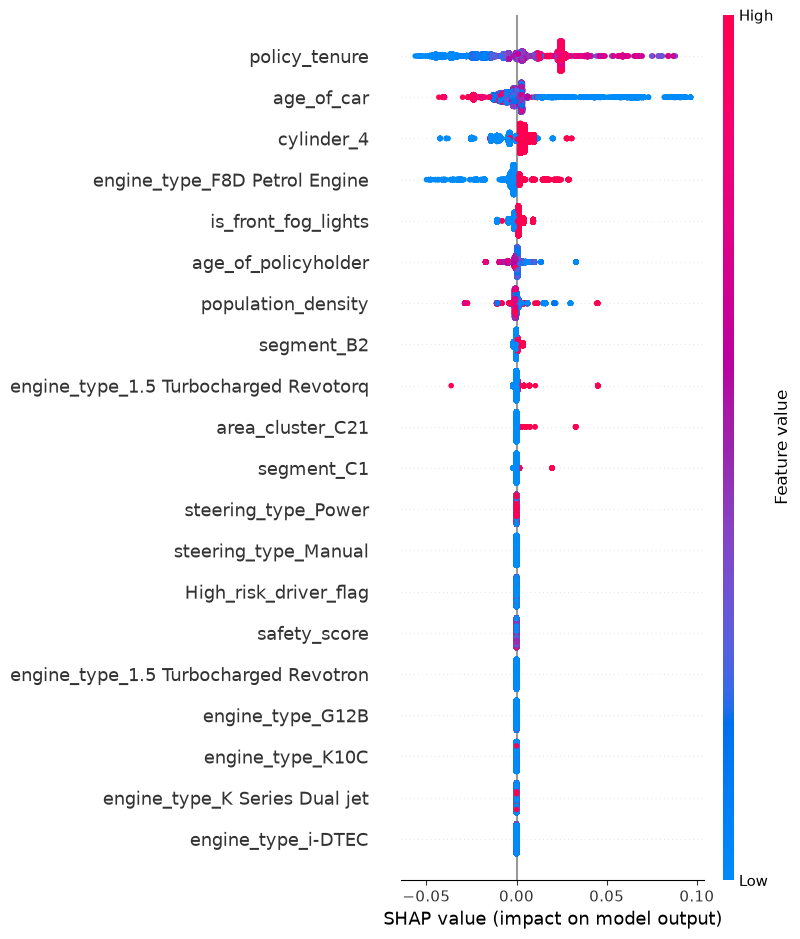

In [88]:
import shap

def _extract_positive_shap(shap_values, X_ref):
    """
    Normalize shap_values to a 2D array (n_samples, n_features) for the positive class.
    Handles:
      - legacy list-of-arrays: [neg_array, pos_array] or [single_array]
      - new 3D-array outputs with class axis in either position
      - 2D-array outputs (assumed already for positive class)
    """
    if isinstance(shap_values, list):
        # legacy list: pick index 1 if present, else 0
        return np.array(shap_values[1] if len(shap_values) > 1 else shap_values[0])

    sv = np.array(shap_values)
    if sv.ndim == 2:
        return sv

    if sv.ndim == 3:
        n_samples = X_ref.shape[0]
        # (n_samples, n_classes, n_features)
        if sv.shape[0] == n_samples:
            return sv[:, 1, :]
        # (n_classes, n_samples, n_features)
        if sv.shape[1] == n_samples:
            return sv[1, :, :]
    raise ValueError(f"Unexpected shap_values shape: {sv.shape}")

# Data to explain
X_explain = X_test.copy()

# 1) DecisionTreeClassifier -> TreeExplainer
explainer_tree = shap.TreeExplainer(dt_best)
shap_vals_tree = explainer_tree.shap_values(X_explain)
shap_pos_tree = _extract_positive_shap(shap_vals_tree, X_explain)
# Ensure shap_pos_tree matches X_explain shape (n_samples, n_features)
sv = np.array(shap_vals_tree)
if sv.ndim == 2:
    shap_pos_tree = sv
elif sv.ndim == 3:
    # (n_samples, n_features, n_classes)
    if sv.shape[0] == X_explain.shape[0] and sv.shape[1] == X_explain.shape[1]:
        shap_pos_tree = sv[:, :, 1]
    # (n_samples, n_classes, n_features)
    elif sv.shape[0] == X_explain.shape[0] and sv.shape[2] == X_explain.shape[1]:
        shap_pos_tree = sv[:, 1, :]
    # (n_classes, n_samples, n_features)
    elif sv.shape[1] == X_explain.shape[0] and sv.shape[2] == X_explain.shape[1]:
        shap_pos_tree = sv[1, :, :]
    else:
        raise ValueError(f"Cannot align shap_vals_tree shape {sv.shape} with X_explain shape {X_explain.shape}")
else:
    raise ValueError(f"Unexpected shap_vals_tree ndim: {sv.ndim}")

shap.summary_plot(shap_pos_tree, X_explain, show=True)



c:\Users\User\AppData\Local\Programs\Python\Python311\Lib\site-packages\shap\explainers\_linear.py:123: FutureWarning:

The feature_perturbation option is now deprecated in favor of using the appropriate masker (maskers.Independent, maskers.Partition or maskers.Impute).



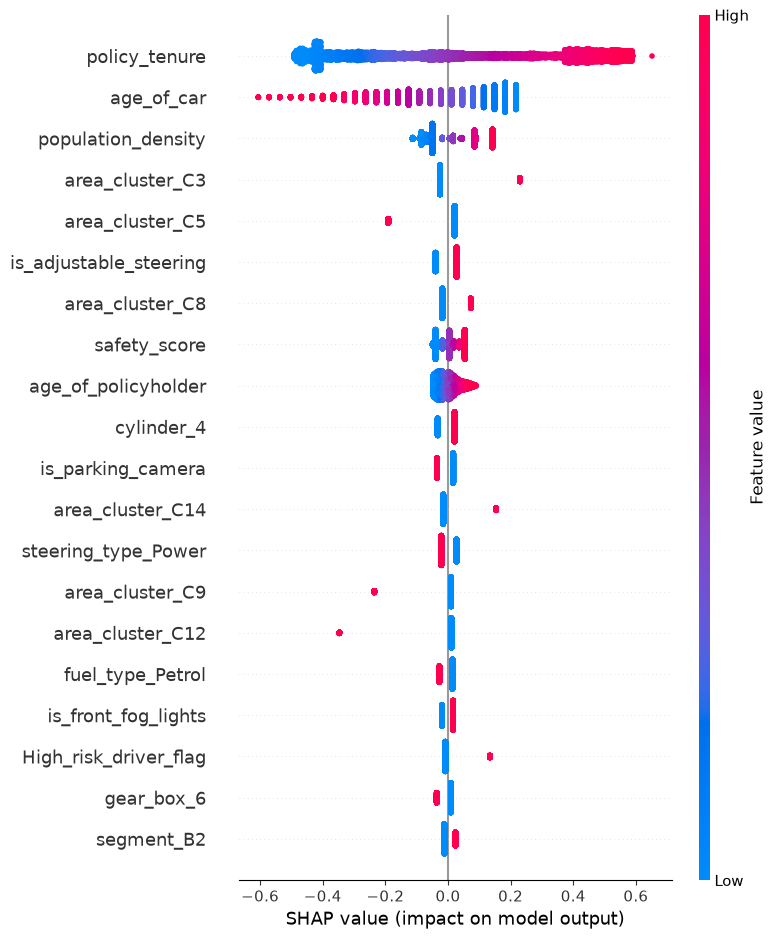

In [89]:
# SHAP explanation for the logistic regression model
# Prepare the explanation dataset from the test set and ensure numeric dtype
X_explain = X_test.copy().astype(float)

# Build a SHAP explainer for the logistic regression model
# Use the training set as the background dataset for the interventional explainer
explainer_lr = shap.LinearExplainer(
    model,
    X_train.astype(float),
    feature_perturbation="interventional"
)

# Compute SHAP values for the explanation dataset
shap_values_lr = explainer_lr.shap_values(X_explain)

# Convert the SHAP output to the positive-class SHAP matrix
shap_pos_lr = _extract_positive_shap(shap_values_lr, X_explain)

# Plot the SHAP summary for the positive class contributions
shap.summary_plot(np.asarray(shap_pos_lr, dtype=np.float64), X_explain, show=True)


In [90]:
# Use the previously computed SHAP values for logistic regression
shap_values = shap_pos_lr
features = X_explain

# Create output directory for SHAP artifacts
shap_out_dir = Path("OUT_DIR")
shap_out_dir.mkdir(parents=True, exist_ok=True)

# Save a summary plot of the SHAP values
shap_plot_path = shap_out_dir / "shap_summary_plot.png"
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, features, max_display=15, show=False)
plt.savefig(shap_plot_path, bbox_inches="tight")
plt.close()

# Build a feature importance summary from SHAP values
shap_feature_summary = pd.DataFrame({
    "feature": features.columns,
    "mean_abs_shap": np.mean(np.abs(shap_values), axis=0),
    "mean_signed_shap": np.mean(shap_values, axis=0),
})

# Determine whether each feature has a net positive, negative, or neutral effect
shap_feature_summary["direction"] = np.where(
    shap_feature_summary["mean_signed_shap"] > 0,
    "positive",
    np.where(shap_feature_summary["mean_signed_shap"] < 0, "negative", "neutral"),
)

# Sort features by the average absolute SHAP contribution
shap_feature_summary = shap_feature_summary.sort_values("mean_abs_shap", ascending=False)

# Save the SHAP feature summary to CSV
csv_path = shap_out_dir / "shap_feature_summary.csv"
shap_feature_summary.to_csv(csv_path, index=False)

# Persist the fitted models alongside the SHAP artifacts
lr_model_path = shap_out_dir / "logistic_regression_model.joblib"
dt_model_path = shap_out_dir / "decision_tree_model.joblib"
joblib.dump(model, lr_model_path)
joblib.dump(dt_best, dt_model_path)

print(f"Saved SHAP summary plot to: {shap_plot_path}")
print(f"Exported SHAP feature summary to: {csv_path}")
print(f"Saved LogisticRegression model to: {lr_model_path}")
print(f"Saved DecisionTree model to: {dt_model_path}")

# Display the top 15 features by SHAP importance
display(shap_feature_summary.head(15))


Saved SHAP summary plot to: OUT_DIR\shap_summary_plot.png
Exported SHAP feature summary to: OUT_DIR\shap_feature_summary.csv
Saved LogisticRegression model to: OUT_DIR\logistic_regression_model.joblib
Saved DecisionTree model to: OUT_DIR\decision_tree_model.joblib


,feature,mean_abs_shap,mean_signed_shap,direction
0,policy_tenure,0.321851,0.039457,positive
1,age_of_car,0.157038,-0.018854,negative
3,population_density,0.076186,-0.002387,negative
33,area_cluster_C3,0.047845,0.002420,positive
35,area_cluster_C5,0.042274,-0.005179,negative
5,is_adjustable_steering,0.032356,0.001506,positive
38,area_cluster_C8,0.031683,0.004305,positive
78,safety_score,0.029748,0.004326,positive
2,age_of_policyholder,0.025745,-0.001030,negative
72,cylinder_4,0.025354,0.001303,positive


In [94]:
# Calculate dynamic risk band cut points using percentiles of predicted probabilities
percentiles = [40, 75, 90]
risk_band_cutpoints = np.percentile(y_test_prob_lr, percentiles)

print("Dynamic Risk Band Cut Points (based on percentiles):")
print(f"40th percentile (Low-Medium threshold): {risk_band_cutpoints[0]:.4f}")
print(f"75th percentile (Medium-High threshold): {risk_band_cutpoints[1]:.4f}")
print(f"90th percentile (High-Very High threshold): {risk_band_cutpoints[2]:.4f}")

# Assign risk bands based on dynamic cut points
def assign_risk_band(prob, cutpoints):
    if prob < cutpoints[0]:
        return 'Low'
    elif prob < cutpoints[1]:
        return 'Medium'
    elif prob < cutpoints[2]:
        return 'High'
    else:
        return 'Very High'
    
risk_bands_test = np.array([assign_risk_band(prob, risk_band_cutpoints) for prob in y_test_prob_lr])

# Create summary statistics by risk band
risk_band_summary = pd.DataFrame({
    'Risk_Band': risk_bands_test,
    'Predicted_Probability': y_test_prob_lr,
    'Actual_Claim': y_test.values
})

risk_band_stats = risk_band_summary.groupby('Risk_Band', observed=True).agg({
    'Predicted_Probability': ['count', 'mean', 'min', 'max'],
    'Actual_Claim': 'sum'
}).round(4)

print("\nRisk Band Statistics (Training Set):")
display(risk_band_stats)

Dynamic Risk Band Cut Points (based on percentiles):
40th percentile (Low-Medium threshold): 0.4484
75th percentile (Medium-High threshold): 0.5645
90th percentile (High-Very High threshold): 0.6175

Risk Band Statistics (Training Set):


Predicted_Probability                         Actual_Claim
                          count    mean     min     max          sum
Risk_Band                                                           
High                       1634  0.5898  0.5645  0.6175          129
Low                        4358  0.3784  0.1753  0.4484          184
Medium                     3814  0.5061  0.4484  0.5645          286
Very High                  1090  0.6458  0.6175  0.7505          110

In [96]:
risk_order = ['Low', 'Medium', 'High', 'Very High']

# Build a dataframe for training predictions and risk levels
prediction_output = pd.DataFrame({
    'risk_level': pd.Categorical(risk_bands_test, categories=risk_order, ordered=True),
    'actual_outcome': y_test.astype(int).values
})

# Compute the average claim rate per ordered risk band
claim_rate_by_band = (
    prediction_output
    .groupby('risk_level', observed=True)['actual_outcome']
    .mean()
    .reindex(risk_order)
)

print("Claim rates by risk level:")
for level, rate in claim_rate_by_band.items():
    print(f"{level}: {rate:.4f}")

# Check whether claim rates increase monotonically across risk bands
monotonic_increase = all(claim_rate_by_band.diff().dropna() >= 0)
print(f"Monotonic increase across bands: {monotonic_increase}")

Claim rates by risk level:
Low: 0.0422
Medium: 0.0750
High: 0.0789
Very High: 0.1009
Monotonic increase across bands: True


In [99]:
# Define the policy column name
policy_col = "policy_id"

# Retrieve policy IDs from the original dataframe, X_train, or use index as fallback
if policy_col in df.columns:
    policy_ids = df.loc[X_test.index, policy_col]
elif policy_col in X_test.columns:
    policy_ids = X_test[policy_col].reindex(X_test.index)
else:
    # Use index as policy identifier if column not found
    policy_ids = pd.Series(X_test.index, index=X_test.index, name=policy_col)

# Compile predictions, actual outcomes, probabilities, and risk levels into a single dataframe
prediction_output = pd.DataFrame({
    policy_col: policy_ids,
    "actual_outcome": y_test.astype(int).values,  # Actual claim outcomes
    "predicted_class": y_test_pred_lr.astype(int),  # Model's binary prediction (0 or 1)
    "claim_probability": y_test_prob_lr,  # Probability of claim from logistic regression
    "risk_level": risk_bands_test  # Assigned risk band (Low/Medium/High/Very High)
})

# Export predictions to CSV file for downstream analysis
prediction_output.to_csv("prediction_output.csv", index=False)

# Display first few rows of the prediction output
display(prediction_output.head())

,policy_id,actual_outcome,predicted_class,claim_probability,risk_level
6208,6208,0,0,0.455253,Medium
9230,9230,0,0,0.395987,Low
20965,20965,0,0,0.354562,Low
22390,22390,0,0,0.399627,Low
20597,20597,0,0,0.469568,Medium
